In [85]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder ,OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score , recall_score , precision_score , f1_score , confusion_matrix , classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

In [2]:
data_set = pd.read_csv("Loan_data.csv")#loading dataset into dataframe
df = pd.DataFrame(data_set)

#Handling missing Numeric and categorical vals using SimpleImputer 
numeric_cols = df.select_dtypes(include=["number"]).columns
cat_cols = df.select_dtypes(include=["object" , "string"]).columns

num_imp = SimpleImputer(strategy="mean")
df[numeric_cols] = num_imp.fit_transform(df[numeric_cols])

cat_imp = SimpleImputer(strategy="most_frequent")
df[cat_cols] = cat_imp.fit_transform(df[cat_cols])
df = df.drop("Applicant_ID" , axis = 1) 


In [ ]:
#Feature engineering using lableEncoder and one hot encoding 
labelEncoder = LabelEncoder()# labelEncoder
df["Loan_Approved"] = labelEncoder.fit_transform(df["Loan_Approved"]) # we want laonCol to be set to 1 and 0 
df["Education_Level"] = labelEncoder.fit_transform(df["Education_Level"]) # same as educationLevel , gard = 0 , not grad = 1

OneHotcols = ["Employment_Status" ,"Marital_Status" ,"Loan_Purpose" ,"Property_Area" , "Gender" , "Employer_Category"] # using OneHotEncoding
OneHot = OneHotEncoder(drop='first' , handle_unknown='ignore' , sparse_output = False) #droping first , handle_unknown ignore , sparse output false 

transform = OneHot.fit_transform(df[OneHotcols]) # transforming the cols to OHE
newData_df = pd.DataFrame(transform , columns=OneHot.get_feature_names_out(OneHotcols) , index = df.index) # creating a new dataFrame of OHE and giving colsName using OneHot.get_feature_names_out(OneHotcols) and index is kept as the df index 

df = pd.concat([df.drop(columns = OneHotcols),newData_df] , axis = 1) #combining  both dataframe horizontally and droping original columns

df

In [9]:
OneHot.get_feature_names_out(OneHotcols)

array(['Employment_Status_Salaried', 'Employment_Status_Self-employed',
       'Employment_Status_Unemployed', 'Marital_Status_Single',
       'Loan_Purpose_Car', 'Loan_Purpose_Education', 'Loan_Purpose_Home',
       'Loan_Purpose_Personal', 'Property_Area_Semiurban',
       'Property_Area_Urban', 'Gender_Male',
       'Employer_Category_Government', 'Employer_Category_MNC',
       'Employer_Category_Private', 'Employer_Category_Unemployed'],
      dtype=object)

<Axes: >

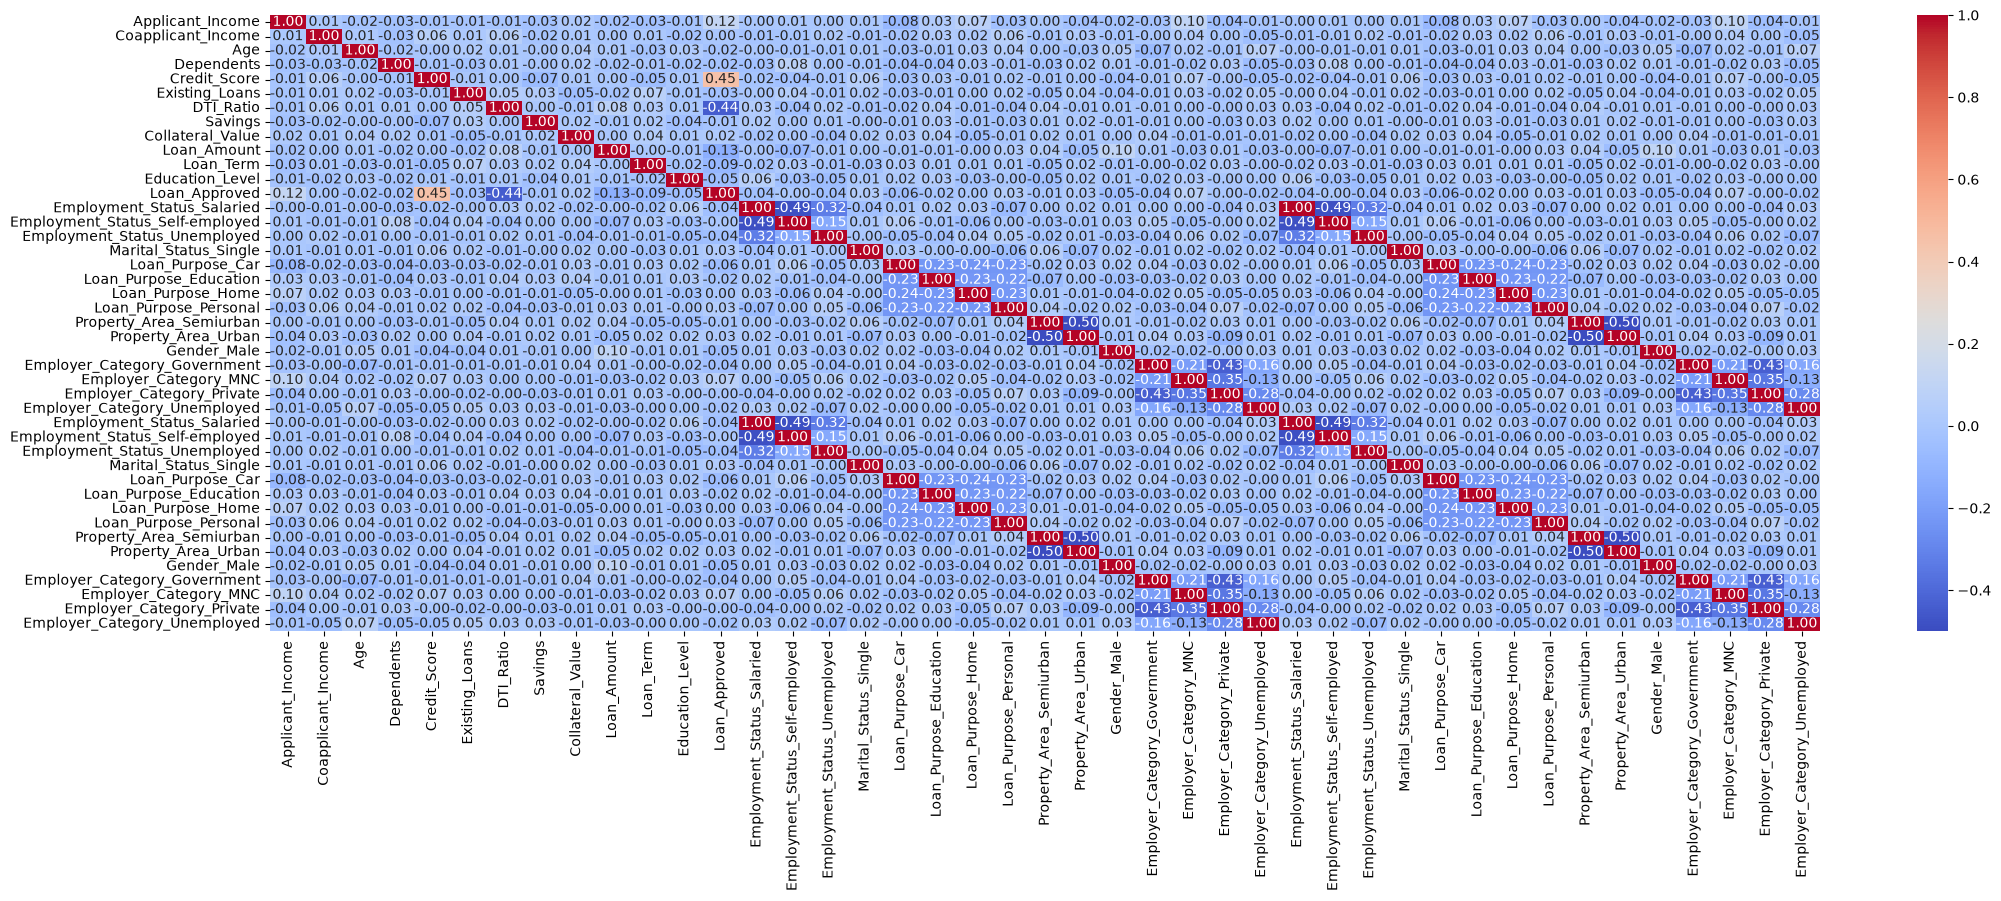

In [25]:
num_cols = df.select_dtypes(include="number") #selecting only num for correaltion
corr_mat = num_cols.corr()

plt.figure(figsize=(25,8)) # figSize larger
sns.heatmap( # for quick insights and data exploration
    corr_mat ,
    annot = True , # actual vals
    cmap = "coolwarm" ,
    fmt = ".2f" # to 2 decimal
)

In [79]:
# Create X and y
X = df.drop(columns=["Loan_Approved"], errors="ignore")
y = df["Loan_Approved"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train model
model = LogisticRegression()

model.fit(X_train_scaled, y_train)

# Predictions
y_pred = model.predict(X_test_scaled)

In [81]:
print("linearRegression")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("CM:" , confusion_matrix(y_test, y_pred))


Output for linearRegression
Accuracy: 0.865
Precision: 0.7833333333333333
Recall: 0.7704918032786885
F1 Score: 0.7768595041322314
CM: [[126  13]
 [ 14  47]]


In [83]:
#kNN 
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train model
model = KNeighborsClassifier(n_neighbors=5)

model.fit(X_train_scaled, y_train)

# Predictions
y_pred = model.predict(X_test_scaled)

In [84]:
print("OutPut for KNeighborsClassifier")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("CM:" , confusion_matrix(y_test, y_pred))

OutPut for KNeighborsClassifier
Accuracy: 0.76
Precision: 0.6274509803921569
Recall: 0.5245901639344263
F1 Score: 0.5714285714285714
CM: [[120  19]
 [ 29  32]]


In [86]:
#NaiveBayes
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train model
model = GaussianNB()

model.fit(X_train_scaled, y_train)

# Predictions
y_pred = model.predict(X_test_scaled)

In [87]:
print("OutPut for  GaussianNB")s
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("CM:" , confusion_matrix(y_test, y_pred))

OutPut for  GaussianNB
Accuracy: 0.865
Precision: 0.8035714285714286
Recall: 0.7377049180327869
F1 Score: 0.7692307692307693
CM: [[128  11]
 [ 16  45]]
